In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

print("Project Root :", PROJECT_ROOT)

Project Root : D:\Research\Papers\Paper_2


In [2]:
import cv2
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10,6)
plt.rcParams["figure.dpi"] = 120

In [3]:
from src.dataset import KITTIOdometryDataset

In [4]:
DATASET = KITTIOdometryDataset(
    r"D:\Research\Papers\Paper_2\datasets\KITTI_Odometry"
)

In [5]:
DATASET.validate()

Color Dataset       : FOUND
Calibration         : FOUND
Ground Truth        : FOUND


In [6]:
summary = DATASET.summary()

display(summary)

,Property,Value
0,Total Sequences,22
1,Training Sequences,11
2,Testing Sequences,11
3,Total Frames,43552
4,Image Width,1241
5,Image Height,376


In [7]:
DATASET.list_sequences()

['00',
 '01',
 '02',
 '03',
 '04',
 '05',
 '06',
 '07',
 '08',
 '09',
 '10',
 '11',
 '12',
 '13',
 '14',
 '15',
 '16',
 '17',
 '18',
 '19',
 '20',
 '21']

In [8]:
DATASET.get_image_size()

(1241, 376)

(376, 1241, 3)


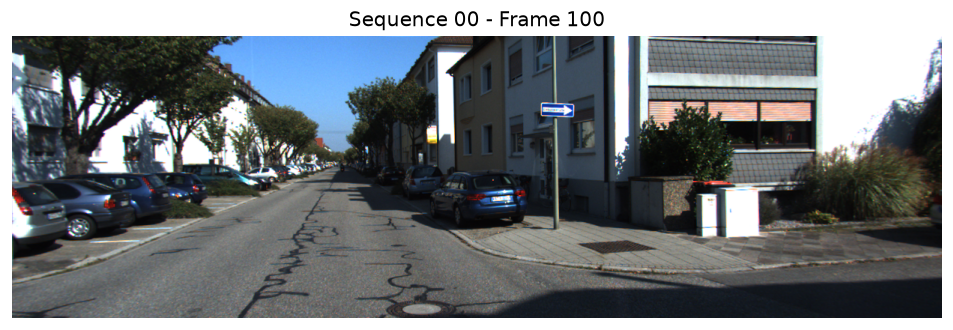

In [9]:
image = DATASET.load_image(
    sequence="00",
    frame=100
)

print(image.shape)

plt.imshow(image)

plt.title("Sequence 00 - Frame 100")

plt.axis("off")

plt.show()

In [10]:
calibration = DATASET.load_calibration("00")

print(calibration.keys())

dict_keys(['P0', 'P1', 'P2', 'P3', 'Tr'])


In [11]:
print(calibration["P2"])

[ 7.188560e+02  0.000000e+00  6.071928e+02  4.538225e+01  0.000000e+00
  7.188560e+02  1.852157e+02 -1.130887e-01  0.000000e+00  0.000000e+00
  1.000000e+00  3.779761e-03]


In [12]:
pose = DATASET.load_pose(
    sequence="00",
    frame=100
)

print(pose)

[ 9.859899e-01  1.389745e-02  1.662252e-01 -4.934649e+00 -1.302694e-02
  9.998951e-01 -6.326123e-03 -2.926167e+00 -1.662957e-01  4.072087e-03
  9.860675e-01  8.431338e+01]


In [13]:
sample = DATASET.load_sample(
    sequence="00",
    frame=100
)

print(sample.keys())

dict_keys(['sequence', 'frame', 'image', 'calibration', 'pose'])


In [14]:
print("Sequence :", sample["sequence"])

print("Frame    :", sample["frame"])

print("Image Shape :", sample["image"].shape)

print("Pose Shape :", sample["pose"].shape)

print("Calibration Keys :", sample["calibration"].keys())

Sequence : 00
Frame    : 100
Image Shape : (376, 1241, 3)
Pose Shape : (12,)
Calibration Keys : dict_keys(['P0', 'P1', 'P2', 'P3', 'Tr'])


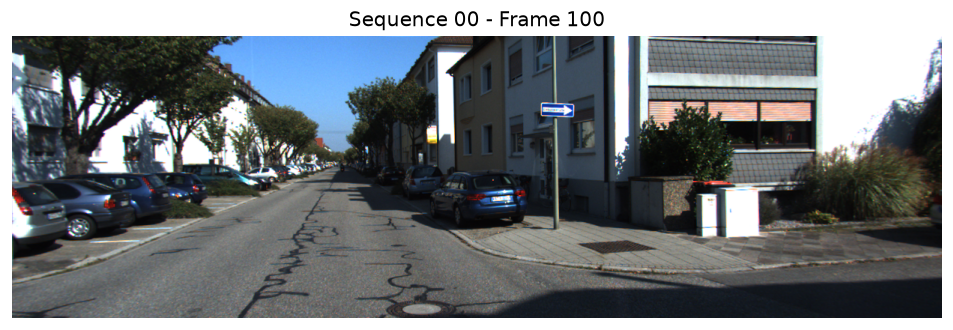

In [15]:
plt.figure(figsize=(10,5))

plt.imshow(sample["image"])

plt.title(
    f"Sequence {sample['sequence']} - Frame {sample['frame']}"
)

plt.axis("off")

plt.show()

In [16]:
print("="*60)

print("DATASET API SUCCESSFULLY VALIDATED")

print("="*60)

DATASET API SUCCESSFULLY VALIDATED
